## Show desired images

In [1]:
## Plot images of each galaxy (stacked) in each filter
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
from astropy.io import fits

# Work from either the repository root or project/; no reduction cells are needed.
project_dir = Path.cwd() if (Path.cwd() / "reduction/stacks").is_dir() else Path.cwd() / "project"
stack_dir = project_dir / "reduction/stacks"
filters = ("g", "r", "i")
display_stride = 2  # Display every second pixel for speed; FITS data are unchanged.
display_percentiles = (1, 99.7)  # Set the contrast independently in each panel.


def show_stacks(galaxy, corrected_m33_r=False):
    # SCI contains the image; the primary HDU contains only metadata.
    # Astropy transparently decompresses the GZIP_2 image extensions.
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    for ax, band in zip(axes, filters):
        corrected = corrected_m33_r and galaxy == "m33" and band == "r"
        filename = f"{galaxy}_{band}_background_corrected.fit" if corrected else f"{galaxy}_{band}_stack.fit"
        path = stack_dir / filename
        with fits.open(path, memmap=False) as hdus:
            full_image = hdus["SCI"].data
            ny, nx = full_image.shape
            image = full_image[::display_stride, ::display_stride].astype(np.float32, copy=True)
            units = hdus["SCI"].header.get("BUNIT", hdus[0].header.get("BUNIT", "ADU/s"))
        finite = image[np.isfinite(image)]
        if not finite.size:
            raise ValueError(f"No finite science pixels in {path}")
        vmin, vmax = np.percentile(finite, display_percentiles)
        if vmax <= vmin:
            vmax = vmin + 1
        # The asinh stretch reveals faint structure without clipping bright sources.
        # Axes are in the original common-grid pixels despite display subsampling.
        im = ax.imshow(image, origin="lower", cmap="gray", interpolation="nearest",
                       extent=(-0.5, nx-0.5, -0.5, ny-0.5),
                       norm=AsinhNorm(vmin=vmin, vmax=vmax, linear_width=(vmax-vmin)/10))
        ax.set(title=f"{band}'" + (" (background corrected)" if corrected else " (original stack)"),
               xlabel="Common-grid x (pixel)", ylabel="Common-grid y (pixel)")
        fig.colorbar(im, ax=ax, label=units, shrink=0.75)
    fig.suptitle("NGC 6503" if galaxy == "ngc6503" else "M33")
    plt.show()


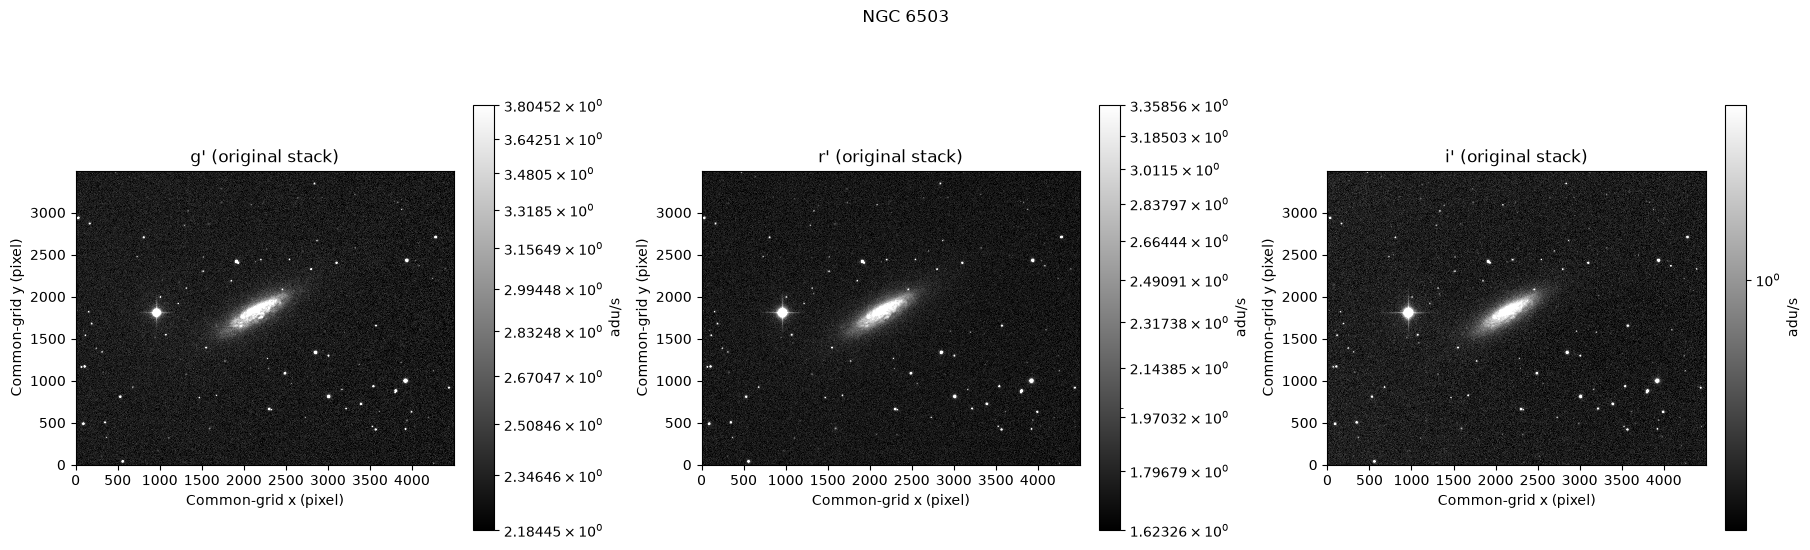

In [2]:
# Show the original g', r', i' master lights for NGC 6503.
show_stacks("ngc6503")


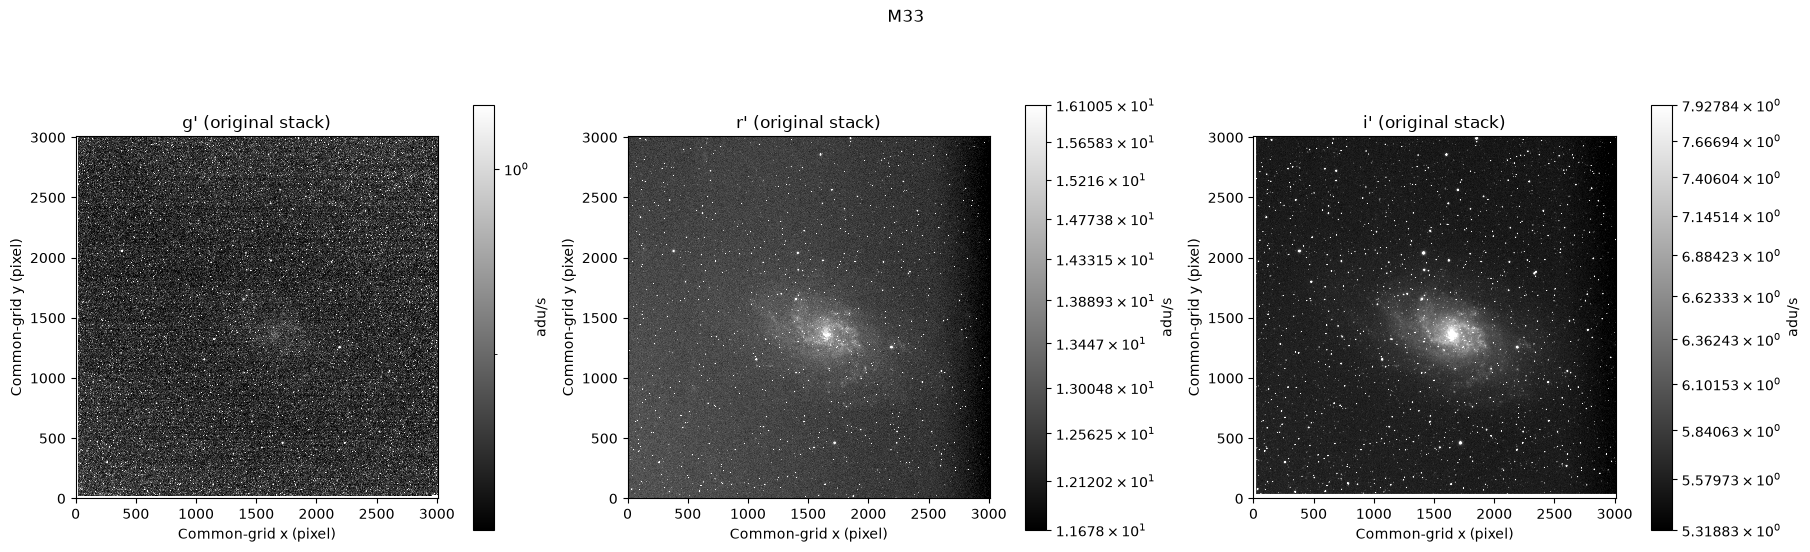

In [3]:
# Show the original g', r', i' master lights for M33.
# These panels have independent stretches and do not represent calibrated colors.
show_stacks("m33")


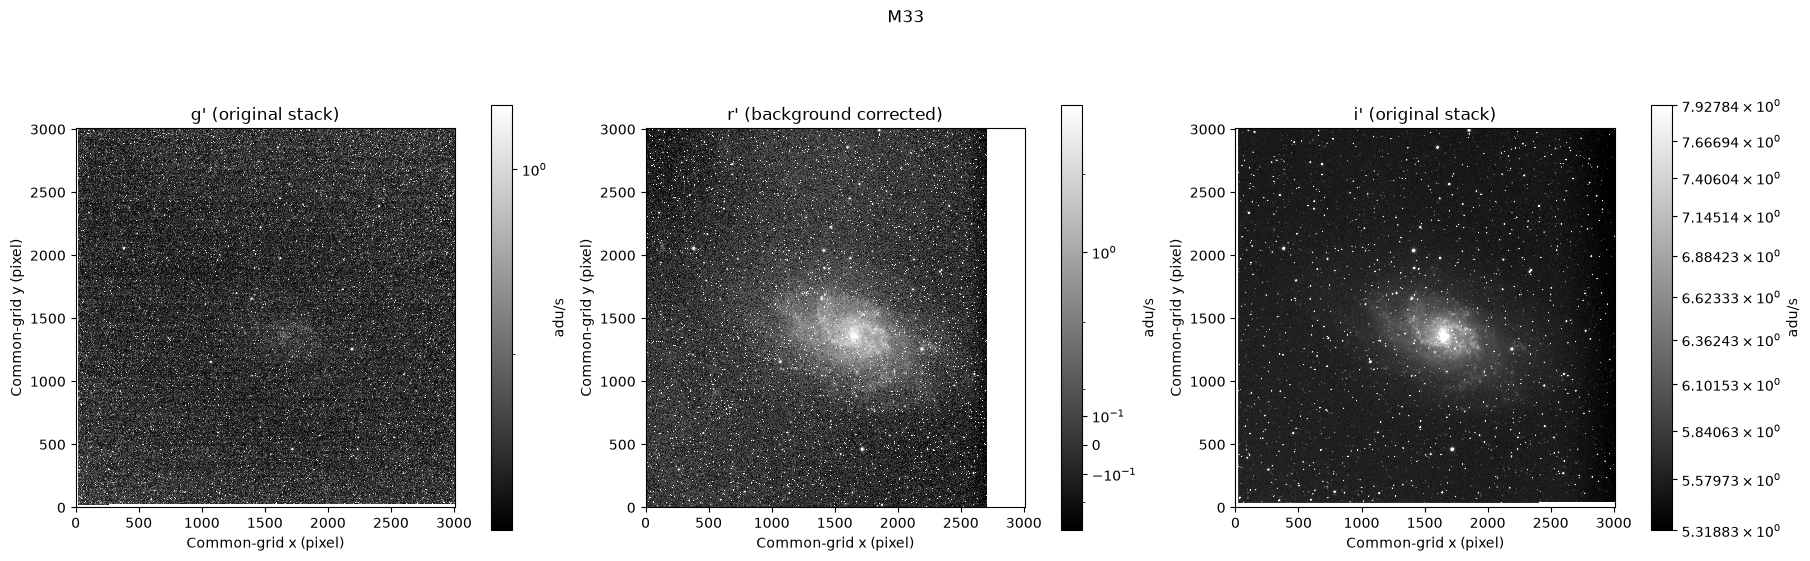

In [5]:
# Optional comparison: switch to True to display the separately corrected M33 r' light.
show_corrected_m33 = True
if show_corrected_m33:
    show_stacks("m33", corrected_m33_r=True)
